In [1]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import datetime as dt
import yfinance as yf
plt.style.use('ggplot')

sentiment_df = pd.read_csv('../../data/sentiment_data.csv')

In [2]:
sentiment_df['date'] = pd.to_datetime(sentiment_df['date'])
sentiment_df = sentiment_df.set_index(['date', 'symbol']) # convert dataframe to MultiIndex
sentiment_df['engagement_ratio'] = sentiment_df['twitterComments'] / sentiment_df['twitterLikes']
sentiment_df = sentiment_df[ # ensure the stock is popular and the engagement is genuine
    (sentiment_df['engagement_ratio'] > 0.1) & 
    (sentiment_df['twitterLikes'] > 20) & 
    (sentiment_df['twitterComments'] > 20)]
sentiment_df


twitterPosts  twitterComments  twitterLikes  \
date       symbol                                                
2021-11-18 AAPL           811.0           2592.0       21674.0   
           AMD            150.0            675.0        2949.0   
           AMZN           557.0           1315.0       12969.0   
           ATVI            82.0             36.0         131.0   
           BA              61.0             55.0         342.0   
...                         ...              ...           ...   
2023-01-04 T              184.0           3409.0       14271.0   
           TSLA          6767.0         540711.0     3810688.0   
           TSN             35.0            168.0         460.0   
           V              132.0           1008.0        5943.0   
           XOM            212.0            374.0        2071.0   

                   twitterImpressions  twitterSentiment  engagement_ratio  
date       symbol                                                          
2021-11-18 AAPL             7981808.0               NaN          0.119590  
           AMD              1645270.0               NaN          0.228891  
           AMZN             5590695.0               NaN          0.101396  
           ATVI             1310715.0               NaN          0.274809  
           BA                425847.0               NaN          0.160819  
...                               ...               ...               ...  
2023-01-04 T                 884935.0          0.590457          0.238876  
           TSLA            55464921.0          0.543057          0.141893  
           TSN                57207.0          0.561900          0.365217  
           V                 139835.0          0.567286          0.169611  
           XOM               483389.0          0.588914          0.180589  

[23336 rows x 6 columns]

In [3]:
aggregated_df = (sentiment_df.reset_index('symbol').groupby([pd.Grouper(freq='M'), 'symbol']))[['engagement_ratio']].mean()
# [pd.Grouper(freq='M'), 'symbol'] means select every unique symbol for every calendar month
# [[]] double square brackets keeps the result as a dataframe instead of collapsing into a Series. Typically used during .groupby()/selection aggregations.
aggregated_df['rank'] = aggregated_df.groupby(level=0)['engagement_ratio'].rank(ascending=False)
filtered_df = aggregated_df[aggregated_df['rank'] < 6]
filtered_df = filtered_df.reset_index(level=1)
filtered_df.index = filtered_df.index + pd.DateOffset(1)
filtered_df = filtered_df.reset_index().set_index(['date', 'symbol'])

dates = filtered_df.index.get_level_values(level=0).unique().tolist()
fixed_dates = {}
for d in dates:
    fixed_dates[d.strftime('%Y-%m-%d')] = filtered_df.xs(d, level=0).index.to_list()

stocks_list = sentiment_df.index.get_level_values(level='symbol').unique().to_list()
first_date = pd.Timestamp(dates[0]) - pd.DateOffset(years=1)
last_date = pd.Timestamp(dates[-1]) + pd.DateOffset(years=1)
prices = yf.download(tickers=stocks_list, start=first_date, end=last_date)['Close']

C:\Users\bedel\AppData\Local\Temp\ipykernel_8048\2359889462.py:1: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  aggregated_df = (sentiment_df.reset_index('symbol').groupby([pd.Grouper(freq='M'), 'symbol']))[['engagement_ratio']].mean()
C:\Users\bedel\AppData\Local\Temp\ipykernel_8048\2359889462.py:18: FutureWarning: YF.download() has changed argument auto_adjust default to True
  prices = yf.download(tickers=stocks_list, start=first_date, end=last_date)['Close']
[*********************100%***********************]  85 of 85 completed

3 Failed downloads:
['K']: YFPricesMissingError('possibly delisted; no price data found  (1d 2020-12-01 00:00:00 -> 2024-02-01 00:00:00) (Yahoo error = "No data found, symbol may be delisted")')
['ATVI', 'MRO']: YFTzMissingError('possibly delisted; no timezone found')


In [4]:
returns_df = np.log(prices).diff().stack().dropna().unstack() # calculate the difference in logged prices to obtain returns
portfolio_df = pd.DataFrame()
for start_date in fixed_dates.keys():
    end_date = (pd.to_datetime(start_date) + pd.offsets.MonthEnd()).strftime('%Y-%m-%d') # gives the end date of the same month
    cols = fixed_dates[start_date]
    available_cols = [col for col in cols if col in returns_df.columns] 
    # only aggregate symbols in fixed_dates for that date if they're in returns_df
    # some symbols may be missing after .diff() calculation
    temp_df = returns_df.loc[start_date:end_date, available_cols].mean(axis=1).to_frame('Portfolio Return')
    # calculate the average return across the top 5 stocks for each date
    portfolio_df = pd.concat([portfolio_df, temp_df], axis=0)

qqq_df = yf.download(tickers='QQQ', start=first_date, end=last_date)
qqq_df.columns = qqq_df.columns.droplevel(1)
qqq_return = np.log(qqq_df['Close']).diff().to_frame('Nasdaq Return')
portfolio_df = portfolio_df.merge(qqq_return, left_index=True, right_index=True)

C:\Users\bedel\AppData\Local\Temp\ipykernel_8048\2900097157.py:13: FutureWarning: YF.download() has changed argument auto_adjust default to True
  qqq_df = yf.download(tickers='QQQ', start=first_date, end=last_date)
[*********************100%***********************]  1 of 1 completed


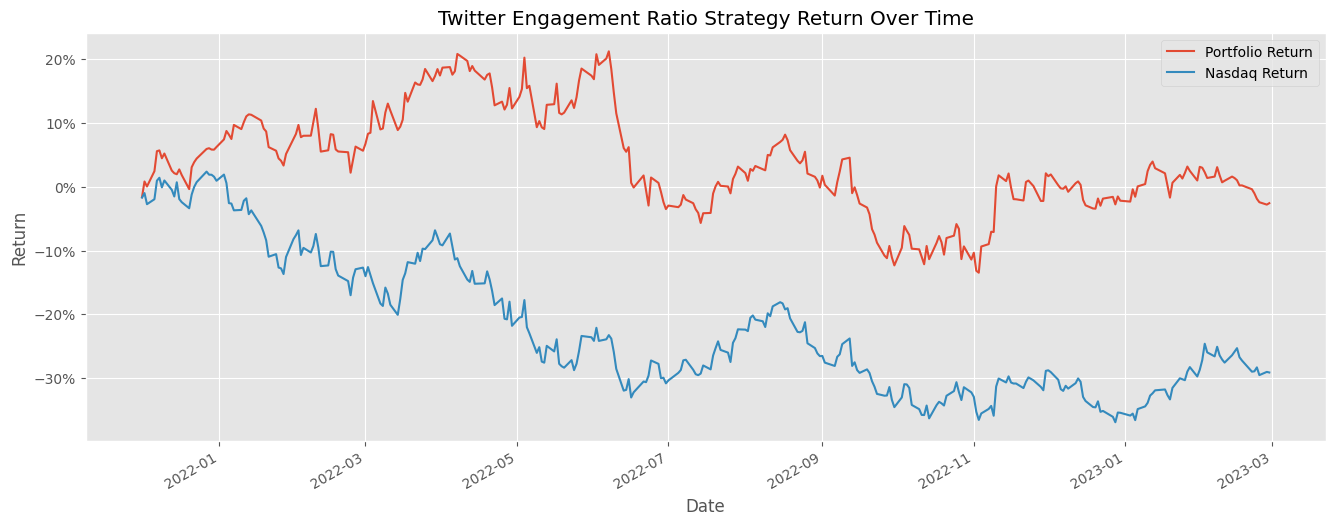

In [5]:
portfolio_cumulative_return = np.exp(np.log1p(portfolio_df).cumsum()).sub(1)
portfolio_cumulative_return.plot(figsize=(16,6))
plt.title('Twitter Engagement Ratio Strategy Return Over Time')
plt.gca().yaxis.set_major_formatter(mtick.PercentFormatter(1))
plt.ylabel('Return')
plt.savefig('../../results/twitter_sentiment_returns.png', dpi=150, bbox_inches='tight')
plt.show()